1. Import the Libraries

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

import tensorflow as tf
from tensorflow.keras import layers, models

# Set random seed
np.random.seed(42)
random.seed(42)
tf.random.set_seed(42)

# Dataset paths
TRAIN_CSV = "data/mitbih_train.csv"
TEST_CSV = "data/mitbih_test.csv"

# Save model files
Path("artifacts").mkdir(exist_ok=True)

# Class labels
classes = ["N", "S", "V", "F", "Q"]

2. Load the Datasets

In [12]:
# Load ECG datasets

test_df = pd.read_csv("/content/mitbih_test.csv.zip", header=None)
train_df = pd.read_csv("/content/mitbih_train.csv.zip", header=None)

# Separate input signals and labels
X_train = train_df.iloc[:, :-1].values.astype(np.float32)
y_train = train_df.iloc[:, -1].values.astype(int)
X_test = test_df.iloc[:, :-1].values.astype(np.float32)
y_test = test_df.iloc[:, -1].values.astype(int)

# Display dataset information
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Training labels:", np.unique(y_train))
print("Testing labels:", np.unique(y_test))

Training data shape: (87554, 187)
Testing data shape: (21892, 187)
Training labels: [0 1 2 3 4]
Testing labels: [0 1 2 3 4]


3. Exploratory Data Analysis (EDA)

0    72471
1     2223
2     5788
3      641
4     6431
Name: count, dtype: int64


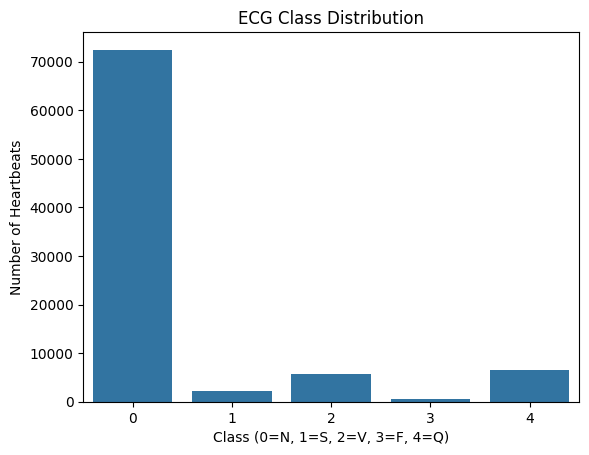

In [14]:
# Count heartbeats in each class
print(pd.Series(y_train).value_counts().sort_index())

# Plot class distribution
sns.countplot(x=y_train)
plt.title("ECG Class Distribution")
plt.xlabel("Class (0=N, 1=S, 2=V, 3=F, 4=Q)")
plt.ylabel("Number of Heartbeats")
plt.show()



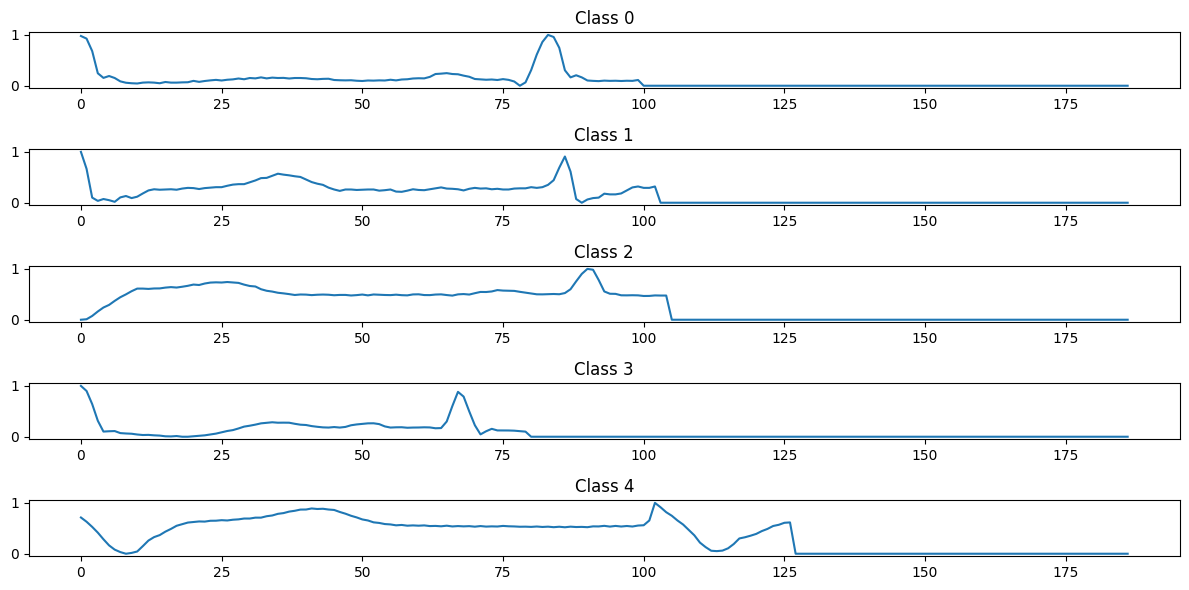

In [15]:
# Plot one ECG signal from each class
plt.figure(figsize=(12, 6))

for i in range(5):
    index = np.where(y_train == i)[0][0]
    plt.subplot(5, 1, i + 1)
    plt.plot(X_train[index])
    plt.title(f"Class {i}")
    plt.tight_layout()

plt.show()

4. Split Training Data into Train and Validate

In [16]:
# Split training data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train,
    test_size=0.15,
    random_state=42,
    stratify=y_train
)

# Reshape data for 1D-CNN
X_train = X_train[..., np.newaxis] # ellipsis
X_val = X_val[..., np.newaxis] # ellipsis
X_test = X_test[..., np.newaxis] # ellipsis

# Display shapes
print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)

Training data: (74420, 187, 1)
Validation data: (13134, 187, 1)
Testing data: (21892, 187, 1)


5. Data Handling

In [17]:
# Calculate class weights
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)

class_weights = dict(enumerate(weights))

print("Class weights:", class_weights)

Class weights: {0: np.float64(0.24162337662337663), 1: np.float64(7.879301217575437), 2: np.float64(3.0252032520325205), 3: np.float64(27.310091743119266), 4: np.float64(2.7230150018294914)}


6. Build 1-D CNN Model

In [18]:
# Build CNN model
model = keras.Sequential([
    layers.Input(shape=(187, 1)),

    layers.Conv1D(32,  kernel_size=7, activation='relu', padding='same'),
    layers.MaxPooling1D(2),

    layers.Conv1D(64, kernel_size=5, activation='relu', padding='same'),
    layers.MaxPooling1D(2),

    layers.Conv1D(128, kernel_size=3, activation='relu', padding='same'),

    layers.GlobalAveragePooling1D(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),

    layers.Dense(5, activation='softmax')
])

# Compile model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 187, 32)        │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 93, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 93, 64)         │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 46, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 46, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 43,845 (171.27 KB)

 Trainable params: 43,845 (171.27 KB)

 Non-trainable params: 0 (0.00 B)

7. Train the model

In [19]:
# Train the CNN model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=256,
    class_weight=class_weights
)

Epoch 1/40
291/291 ━━━━━━━━━━━━━━━━━━━━ 42s 138ms/step - accuracy: 0.2288 - loss: 1.3579 - val_accuracy: 0.1964 - val_loss: 1.3735
Epoch 2/40
291/291 ━━━━━━━━━━━━━━━━━━━━ 41s 139ms/step - accuracy: 0.4044 - loss: 0.9473 - val_accuracy: 0.4305 - val_loss: 1.1902
Epoch 3/40
291/291 ━━━━━━━━━━━━━━━━━━━━ 39s 134ms/step - accuracy: 0.5056 - loss: 0.7801 - val_accuracy: 0.6366 - val_loss: 0.8273
Epoch 4/40
291/291 ━━━━━━━━━━━━━━━━━━━━ 42s 137ms/step - accuracy: 0.5755 - loss: 0.6864 - val_accuracy: 0.7262 - val_loss: 0.7252
Epoch 5/40
291/291 ━━━━━━━━━━━━━━━━━━━━ 40s 137ms/step - accuracy: 0.6231 - loss: 0.6344 - val_accuracy: 0.7329 - val_loss: 0.7035
Epoch 6/40
291/291 ━━━━━━━━━━━━━━━━━━━━ 40s 137ms/step - accuracy: 0.6626 - loss: 0.5983 - val_accuracy: 0.7428 - val_loss: 0.6902
Epoch 7/40
291/291 ━━━━━━━━━━━━━━━━━━━━ 39s 134ms/step - accuracy: 0.6895 - loss: 0.5619 - val_accuracy: 0.6830 - val_loss: 0.7626
Epoch 8/40
291/291 ━━━━━━━━━━━━━━━━━━━━ 39s 135ms/step - accuracy: 0.7197 - loss: 0

8. Training and Validation Accuracy

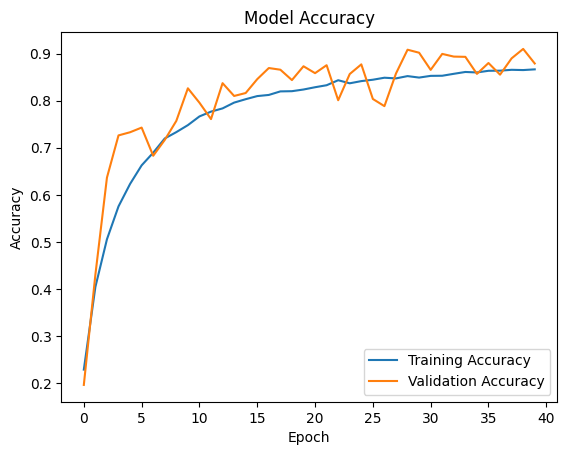

In [20]:
# Plot training and validation accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

9.Training and Validation Loss

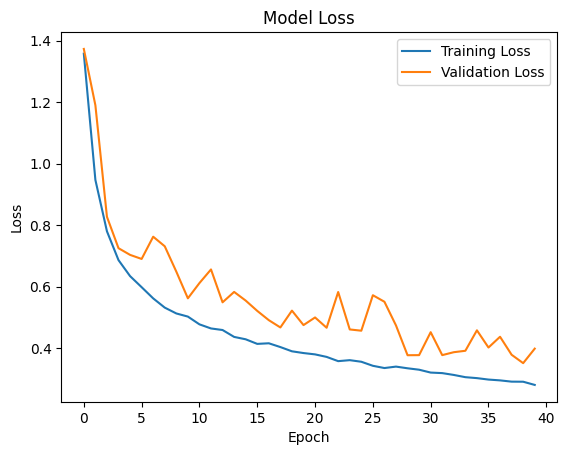

In [21]:
# Plot training and validation loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

10. Model Testing and Evaluation

In [26]:
# Predict test data
predictions = model.predict(X_test)
y_pred = np.argmax(predictions, axis=1)

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=classes))

685/685 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step
Accuracy: 0.8723277909738717

Classification Report:
              precision    recall  f1-score   support

           N       0.99      0.86      0.92     18118
           S       0.23      0.81      0.36       556
           V       0.77      0.94      0.85      1448
           F       0.19      0.86      0.32       162
           Q       0.90      0.98      0.94      1608

    accuracy                           0.87     21892
   macro avg       0.62      0.89      0.68     21892
weighted avg       0.94      0.87      0.90     21892



11. Confusion Matrix

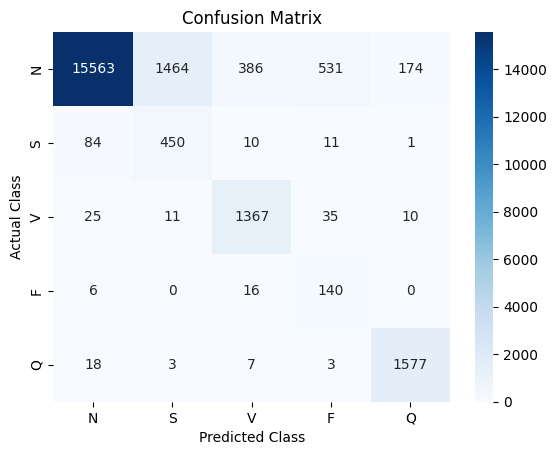

In [28]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)


plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix")
plt.show()

12. Display ECG Predictions

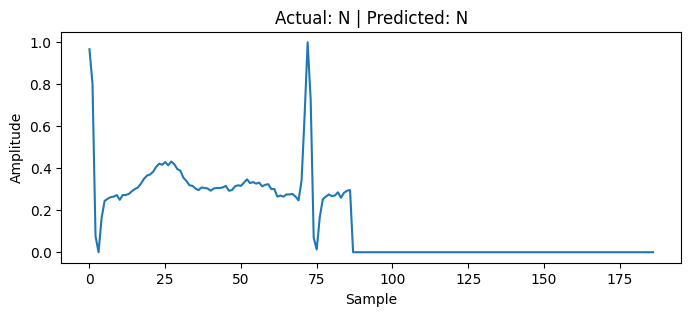

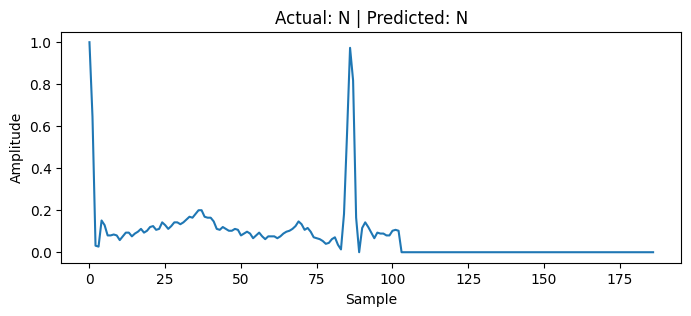

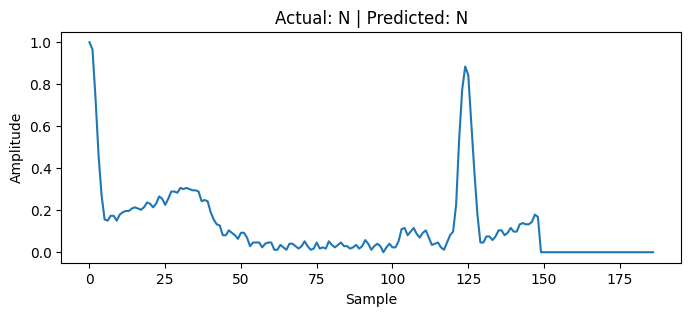

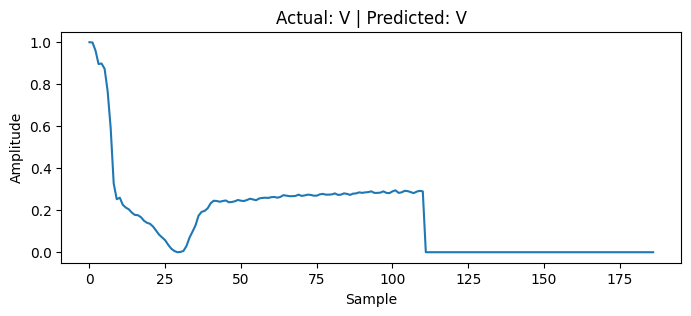

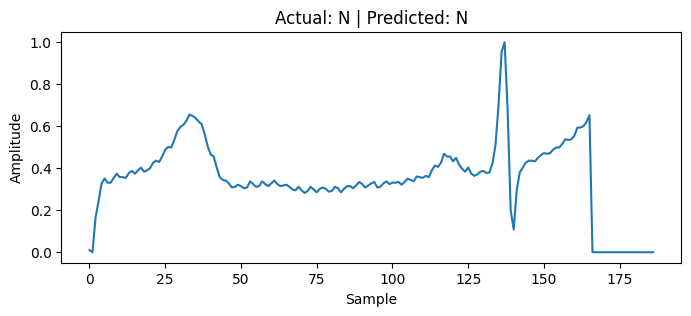

In [29]:
import matplotlib.pyplot as plt
import numpy as np

# Select 5 random ECG signals
indices = np.random.choice(len(X_test), min(5, len(X_test)), replace=False)

for i in indices:
    plt.figure(figsize=(8, 3))

    # Plot ECG signal
    plt.plot(X_test[i].flatten())

    # Get actual and predicted classes
    actual = classes [int(y_test[i])]
    predicted = classes [int(y_pred[i])]

    plt.title(f"Actual: {actual} | Predicted: {predicted}")
    plt.xlabel("Sample")
    plt.ylabel("Amplitude")
    plt.show()

13. Save the model

In [30]:
import json
from pathlib import Path

# Create folder to save files
Path("artifacts").mkdir(exist_ok=True)

# Save trained model
model.save("artifacts/ecg_arrhythmia_cnn.keras")

# Save class names
metadata = {
    "classes": ["N", "S", "V", "F", "Q"]
}

with open("artifacts/metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Model and metadata saved successfully!")

Model and metadata saved successfully!


14. Predict ECG Heartbeat

In [32]:
import numpy as np

def predict_heartbeat(signal):
    signal = np.array(signal).reshape(1, 187, 1)

    # Predict heartbeat class
    probabilities = model.predict(signal, verbose=0)[0]
    predicted_class = np.argmax(probabilities)

    print("Predicted Class:", classes [predicted_class])
    print("Probability:", round(float(probabilities[predicted_class]), 3))

# Test using one ECG signal
predict_heartbeat(X_test[0])

Predicted Class: N
Probability: 0.95
